# Canadian household spending

Source: Statistics Canada table 11-10-0222-01 (average household spending, annual). Run all cells; charts go to `outputs/` and the table behind them to `analysis_ready/`.

In [1]:
import warnings
warnings.filterwarnings('ignore')
import logging
import re
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
pd.options.display.max_colwidth = 90
pd.options.display.float_format = "{:,.2f}".format


def find_hub_root():
    """Walk up from this notebook's folder until we find the hub (it contains processed/statcan)."""
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / "processed" / "statcan").exists():
            return folder
    raise FileNotFoundError(
        "Could not find the hub folder (a folder that contains processed/statcan). "
        "Open this notebook from inside the repository and run the download script first."
    )


HUB = find_hub_root()
OUTPUTS = HUB / "outputs"                # charts are saved here
ANALYSIS_READY = HUB / "analysis_ready"  # summary tables are saved here
OUTPUTS.mkdir(exist_ok=True)
ANALYSIS_READY.mkdir(exist_ok=True)


# Chart style: light surface, thin lines, quiet grid. Colours are used in a fixed order
# (blue, orange, aqua, ...) so a series keeps the same colour in every chart. Gray is for context.
SURFACE, INK, INK2 = "#fcfcfb", "#0b0b0b", "#52514e"
GRID, AXIS, MUTED = "#e1e0d9", "#c3c2b7", "#898781"
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, RED = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#e34948"
)
SERIES_COLOURS = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN]

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "Helvetica Neue", "Arial", "DejaVu Sans"],
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "lines.linewidth": 2, "figure.dpi": 110,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.titlecolor": INK, "legend.frameon": False,
})


def subtitle(ax, text):
    """Small grey line under the chart title (we use it to show exactly which series is plotted)."""
    ax.text(0, 1.02, text, transform=ax.transAxes, fontsize=9.5, color=INK2, va="bottom", ha="left")


def spread(values, min_gap):
    """Nudge label positions apart so direct labels do not overlap."""
    values = np.asarray(values, dtype=float)
    order = np.argsort(values)
    pos = values[order].copy()
    for i in range(1, len(pos)):
        if pos[i] - pos[i - 1] < min_gap:
            pos[i] = pos[i - 1] + min_gap
    out = np.empty_like(pos)
    out[order] = pos
    return out


def direct_labels(ax, items):
    """Label each line at its right-hand end. items = [(text, series), ...]"""
    low, high = ax.get_ylim()
    ys = spread([s.iloc[-1] for _, s in items], 0.06 * (high - low))
    for (text, s), y in zip(items, ys):
        ax.annotate(text, (s.index[-1], y), xytext=(6, 0), textcoords="offset points",
                    va="center", fontsize=9, color=INK2)


def save_fig(fig, name):
    path = OUTPUTS / f"{name}.png"
    fig.savefig(path, dpi=150, bbox_inches="tight")
    print("Saved chart:", path.relative_to(HUB))


def clean_unit(text):
    """'Persons in thousands, thousands' -> 'Persons in thousands' (drop a repeated scale word)."""
    kept = []
    for part in [p.strip() for p in str(text).split(",")]:
        if part and not any(part.lower() in k.lower() for k in kept):
            kept.append(part)
    return ", ".join(kept)


def load_table(table_number):
    """Read the processed file for a Statistics Canada table, e.g. '14-10-0287-01'."""
    pid = re.sub(r"\D", "", table_number)[:8]
    matches = sorted((HUB / "processed" / "statcan").glob(f"statcan_{pid}_*/statcan_{pid}_*.csv"))
    if not matches:
        raise FileNotFoundError(f"No processed file for table {table_number}. Run the download script first.")
    if len(matches) > 1:
        print("Several files found, using the first:", [m.name for m in matches])
    frame = pd.read_csv(
        matches[0], dtype={"geography": str, "series": str, "unit": str, "status": str},
        na_values=[""], keep_default_na=False,
    )
    frame["date"] = pd.to_datetime(frame["date"], errors="coerce")
    frame["value"] = pd.to_numeric(frame["value"], errors="coerce")
    return frame, matches[0]


df, path = load_table("11-10-0222-01")

GEO = "Canada" if "Canada" in set(df["geography"]) else sorted(df["geography"].unique())[0]
nat = df[df["geography"] == GEO]
LATEST = nat["date"].max()
FIRST = nat["date"].min()
UNIT = clean_unit(nat["unit"].dropna().mode().iloc[0]) if nat["unit"].notna().any() else ""


TOTAL_SERIES = None      # set to an exact series name to override
SHELTER_SERIES = None    # same, for the shelter row

wide = nat.pivot_table(index="date", columns="series", values="value", aggfunc="first").sort_index()
means = wide.mean()
if TOTAL_SERIES is None:
    candidates = [s for s in wide.columns if "total expenditure" in s.lower()]
    TOTAL_SERIES = candidates[0] if candidates else means.idxmax()

cats = [c for c in wide.columns if c != TOTAL_SERIES and "total" not in c.lower()]
if SHELTER_SERIES is None:
    shelter = [c for c in cats if c.strip().lower() == "shelter"] or sorted([c for c in cats if "shelter" in c.lower()], key=len)
    SHELTER_SERIES = shelter[0] if shelter else None

ratio = wide[cats].sum(axis=1) / wide[TOTAL_SERIES]


def money(v):
    return f"${v:,.0f}" if UNIT.lower().startswith("dollar") else f"{v:,.0f}"

Saved chart: outputs\household_total_spending.png


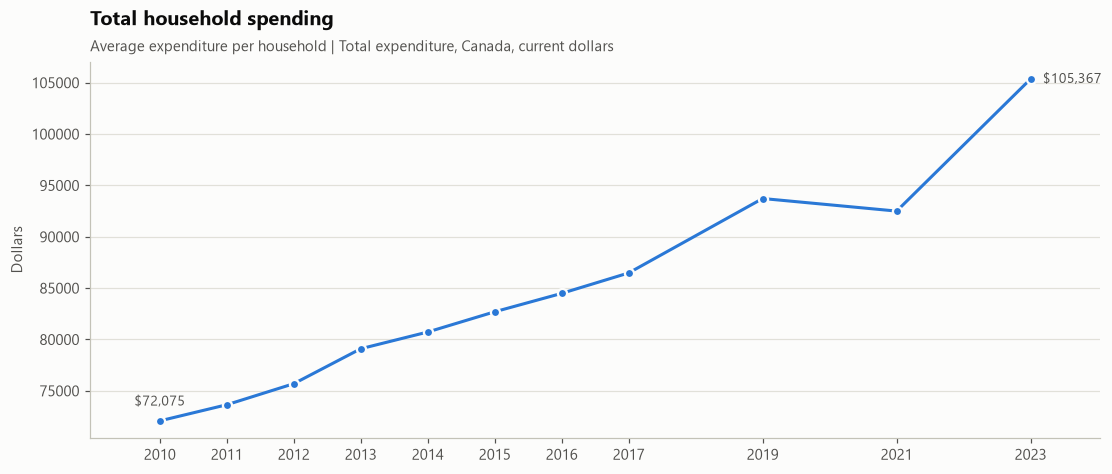

### Findings
- **Level:** average household spending reached **$105,367** in 2023, up 46% from $72,075 in 2010 (about 3.0% a year).
- **Fastest year:** 2023 (+13.9%). **Weakest year:** 2021 (-1.3%).
- **Note:** these are current dollars, so part of the rise is just inflation.

In [2]:
total = wide[TOTAL_SERIES].dropna()
years = total.index.year

fig, ax = plt.subplots(figsize=(10, 4.2), constrained_layout=True)
ax.plot(years, total.values, color=BLUE, marker="o", ms=6, mec=SURFACE, mew=1.5)
ax.set_xticks(years)
ax.margins(x=0.08)
ax.set_ylabel(UNIT)
ax.set_title("Total household spending", pad=24)
subtitle(ax, f"{TOTAL_SERIES}, {GEO}, current dollars")
ax.annotate(money(total.iloc[-1]), (years[-1], total.iloc[-1]), xytext=(8, 0), textcoords="offset points",
            va="center", fontsize=9, color=INK2)
ax.annotate(money(total.iloc[0]), (years[0], total.iloc[0]), xytext=(0, 10), textcoords="offset points",
            ha="center", fontsize=9, color=INK2)
save_fig(fig, "household_total_spending")
plt.show()

yrs = total.index.year[-1] - total.index.year[0]
cagr = ((total.iloc[-1] / total.iloc[0]) ** (1 / yrs) - 1) * 100 if yrs else float("nan")
yoy = total.pct_change().dropna() * 100
display(Markdown("### Findings\n" + "\n".join([
    f"- **Level:** average household spending reached **{money(total.iloc[-1])}** in {total.index[-1]:%Y}, up {(total.iloc[-1] / total.iloc[0] - 1) * 100:.0f}% from {money(total.iloc[0])} in {total.index[0]:%Y} (about {cagr:.1f}% a year).",
    f"- **Fastest year:** {yoy.idxmax():%Y} ({yoy.max():+.1f}%). **Weakest year:** {yoy.idxmin():%Y} ({yoy.min():+.1f}%).",
    "- **Note:** these are current dollars, so part of the rise is just inflation.",
])))


Saved chart: outputs\household_spending_by_category.png


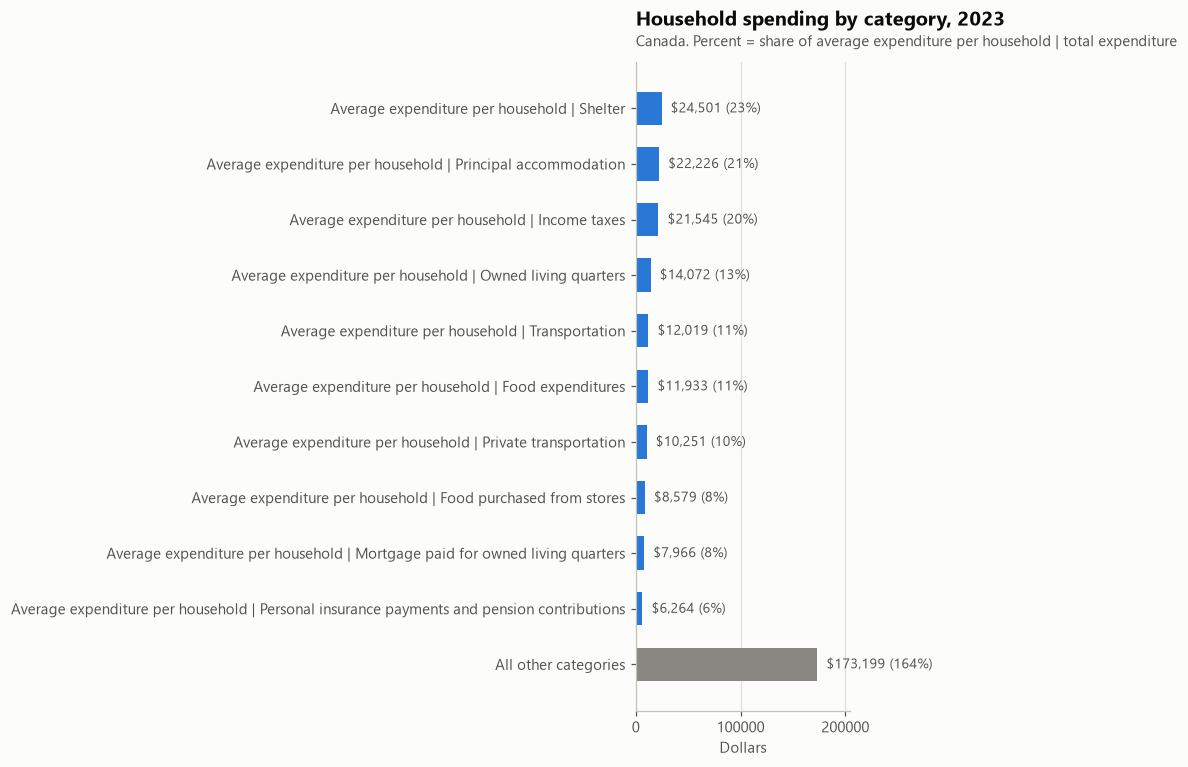

### Findings
- **Biggest item:** Average expenditure per household | Shelter takes **23%** of the budget ($24,501). The top three (Average expenditure per household | Shelter, Average expenditure per household | Principal accommodation, Average expenditure per household | Income taxes) together are 65%.
- **Fastest growing since 2010:** Average expenditure per household | Digital services (+3657%); slowest: Average expenditure per household | Discounts and refunds (-96%).
- **Shifting share:** Average expenditure per household | Income taxes had the largest change in share of spending (+3.3 points); Average expenditure per household | Private transportation had the smallest (-4.3 points).
- **Why it matters for risk:** the bigger the share tied up in essentials such as housing, the less room households have to absorb an income shock.

Saved table: analysis_ready\household_spending_by_category_annual.csv


In [3]:
latest_vals = wide.loc[LATEST, cats].dropna().sort_values(ascending=False)
top = latest_vals.head(10)
rest = latest_vals.iloc[10:].sum()
bars = pd.concat([top, pd.Series({"All other categories": rest})]) if len(latest_vals) > 10 else top
total_latest = wide.loc[LATEST, TOTAL_SERIES]

fig, ax = plt.subplots(figsize=(10, 0.46 * len(bars) + 1.8), constrained_layout=True)
colours = [BLUE] * len(top) + ([MUTED] if len(latest_vals) > 10 else [])
ypos = np.arange(len(bars))
ax.barh(ypos, bars.values, height=0.6, color=colours)
ax.set_yticks(ypos)
ax.set_yticklabels(bars.index)
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.margins(x=0.18)
ax.set_xlabel(UNIT)
ax.set_title(f"Household spending by category, {LATEST:%Y}", pad=24)
subtitle(ax, f"{GEO}. Percent = share of {TOTAL_SERIES.lower()}")
for y, v in zip(ypos, bars.values):
    ax.annotate(f"{money(v)} ({v / total_latest:.0%})", (v, y), xytext=(6, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK2)
save_fig(fig, "household_spending_by_category")
plt.show()

shares = latest_vals / total_latest * 100
growth = ((wide.loc[LATEST, cats] / wide.loc[FIRST, cats] - 1) * 100).dropna().sort_values(ascending=False)
share_change = (wide.loc[LATEST, cats] / wide.loc[LATEST, TOTAL_SERIES] - wide.loc[FIRST, cats] / wide.loc[FIRST, TOTAL_SERIES]) * 100
share_change = share_change.dropna().sort_values()
display(Markdown("### Findings\n" + "\n".join([
    f"- **Biggest item:** {shares.index[0]} takes **{shares.iloc[0]:.0f}%** of the budget ({money(latest_vals.iloc[0])}). The top three ({', '.join(shares.index[:3])}) together are {shares.iloc[:3].sum():.0f}%.",
    f"- **Fastest growing since {FIRST:%Y}:** {growth.index[0]} ({growth.iloc[0]:+.0f}%); slowest: {growth.index[-1]} ({growth.iloc[-1]:+.0f}%).",
    f"- **Shifting share:** {share_change.index[-1]} had the largest change in share of spending ({share_change.iloc[-1]:+.1f} points); {share_change.index[0]} had the smallest ({share_change.iloc[0]:+.1f} points).",
    "- **Why it matters for risk:** the bigger the share tied up in essentials such as housing, the less room households have to absorb an income shock.",
])))

table = wide[[TOTAL_SERIES, *cats]].copy()
table.index = table.index.year
table.index.name = "year"
table.to_csv(ANALYSIS_READY / "household_spending_by_category_annual.csv")
print("Saved table:", (ANALYSIS_READY / "household_spending_by_category_annual.csv").relative_to(HUB))
